# 1.2. Estadística descriptiva y gráficos

In [1]:
SEMILLA = 42

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ruta_csv = next(
    carpeta / "data" / "raw" / "weatherAUS.csv"
    for carpeta in (Path.cwd(), *Path.cwd().parents)
    if (carpeta / "data" / "raw" / "weatherAUS.csv").is_file()
)
datos = pd.read_csv(ruta_csv)
assert datos.shape == (145_460, 23), f"Dimensiones inesperadas: {datos.shape}"
print(f"Filas: {len(datos):,} | Columnas: {datos.shape[1]}".replace(",", "."))

Filas: 145.460 | Columnas: 23


## Resumen de variables numéricas

In [2]:
numericas = datos.select_dtypes(include="number")
resumen = pd.DataFrame({
    "N válido": numericas.count(),
    "Media": numericas.mean(),
    "Mediana": numericas.median(),
    "Desviación estándar": numericas.std(),
    "Mínimo": numericas.min(),
    "Máximo": numericas.max(),
    "Rango intercuartílico": numericas.quantile(0.75) - numericas.quantile(0.25),
})
display(resumen.round(2))

,N válido,Media,Mediana,Desviación estándar,Mínimo,Máximo,Rango intercuartílico
MinTemp,143975,12.19,12.0,6.40,-8.5,33.9,9.3
MaxTemp,144199,23.22,22.6,7.12,-4.8,48.1,10.3
Rainfall,142199,2.36,0.0,8.48,0.0,371.0,0.8
Evaporation,82670,5.47,4.8,4.19,0.0,145.0,4.8
Sunshine,75625,7.61,8.4,3.79,0.0,14.5,5.8
WindGustSpeed,135197,40.04,39.0,13.61,6.0,135.0,17.0
WindSpeed9am,143693,14.04,13.0,8.92,0.0,130.0,12.0
WindSpeed3pm,142398,18.66,19.0,8.81,0.0,87.0,11.0
Humidity9am,142806,68.88,70.0,19.03,0.0,100.0,26.0
Humidity3pm,140953,51.54,52.0,20.80,0.0,100.0,29.0


## Distribución de RainTomorrow y datos faltantes

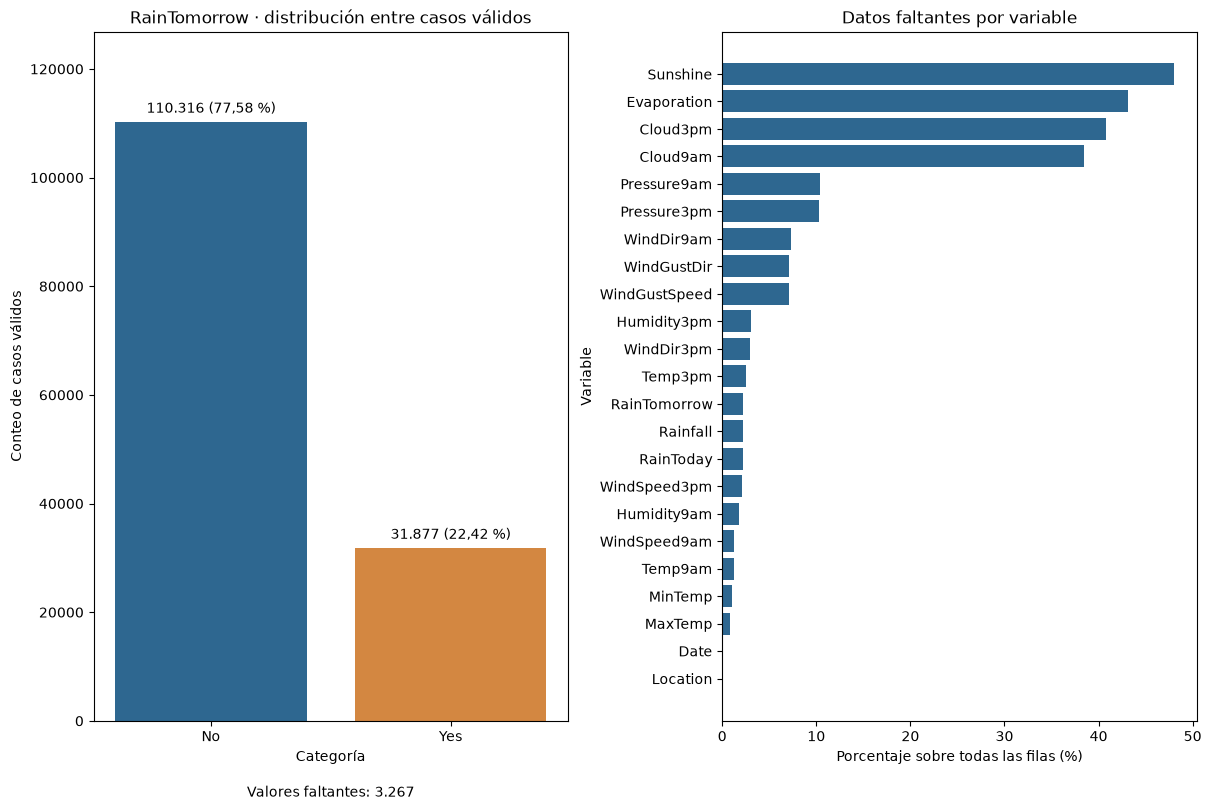

,Conteo de faltantes,Porcentaje de faltantes (%)
Variable,,
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06


In [3]:
objetivo = datos["RainTomorrow"]
conteos = objetivo.value_counts()
porcentajes = conteos.div(objetivo.count()).mul(100)

faltantes = datos.isna().sum().sort_values(ascending=False)
tabla_faltantes = pd.DataFrame({
    "Conteo de faltantes": faltantes,
    "Porcentaje de faltantes (%)": faltantes.div(len(datos)).mul(100),
})
tabla_faltantes.index.name = "Variable"

fig, (ax_objetivo, ax_faltantes) = plt.subplots(
    1, 2, figsize=(12, 8), layout="constrained"
)

barras = ax_objetivo.bar(conteos.index, conteos, color=["#2E6790", "#D38741"])
etiquetas = [
    f"{n:,}".replace(",", ".") + f" ({porcentajes[categoria]:.2f} %)".replace(".", ",")
    for categoria, n in conteos.items()
]
ax_objetivo.bar_label(barras, labels=etiquetas, padding=4)
ax_objetivo.set_ylim(0, conteos.max() * 1.15)
ax_objetivo.set(
    title="RainTomorrow · distribución entre casos válidos",
    xlabel="Categoría",
    ylabel="Conteo de casos válidos",
)
ax_objetivo.text(
    0.5, -0.11, f"Valores faltantes: {objetivo.isna().sum():,}".replace(",", "."),
    transform=ax_objetivo.transAxes, ha="center",
)

ax_faltantes.barh(
    tabla_faltantes.index, tabla_faltantes["Porcentaje de faltantes (%)"],
    color="#2E6790",
)
ax_faltantes.invert_yaxis()
ax_faltantes.set(
    title="Datos faltantes por variable",
    xlabel="Porcentaje sobre todas las filas (%)",
    ylabel="Variable",
)
plt.show()
display(tabla_faltantes.round(2))

## Distribuciones de Humidity3pm y Rainfall

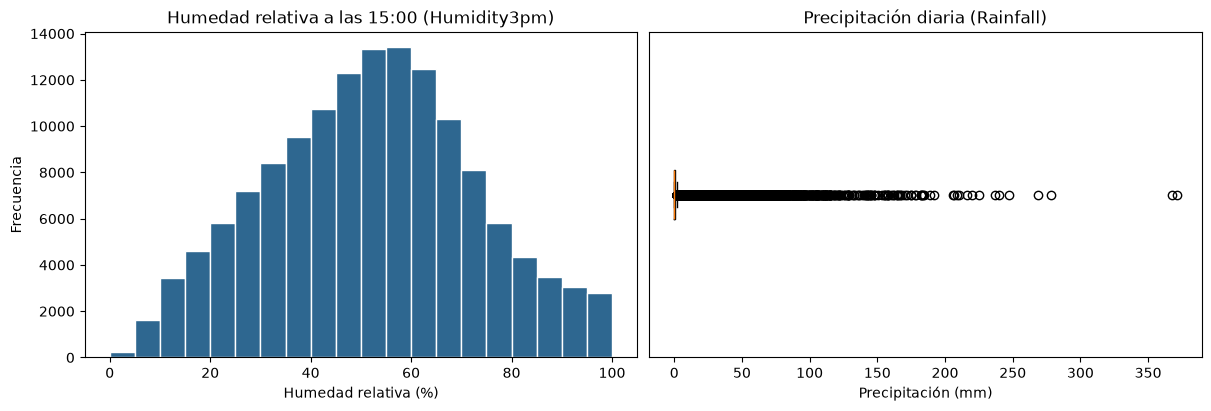

In [4]:
fig, (ax_humedad, ax_lluvia) = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)
ax_humedad.hist(
    datos["Humidity3pm"].dropna(), bins=20, range=(0, 100),
    color="#2E6790", edgecolor="white",
)
ax_humedad.set(
    title="Humedad relativa a las 15:00 (Humidity3pm)",
    xlabel="Humedad relativa (%)",
    ylabel="Frecuencia",
)

ax_lluvia.boxplot(datos["Rainfall"].dropna(), orientation="horizontal")
ax_lluvia.set(
    title="Precipitación diaria (Rainfall)",
    xlabel="Precipitación (mm)",
    yticks=[],
)
plt.show()

## Copias exactas y claves repetidas

In [5]:
clave = datos[["Date", "Location"]]
filas_con_clave_repetida = clave.duplicated(keep=False)

verificacion = pd.Series({
    "Copias exactas adicionales": datos.duplicated().sum(),
    "Claves Date + Location distintas que se repiten": (
        clave.loc[filas_con_clave_repetida].drop_duplicates().shape[0]
    ),
    "Filas con clave repetida, incluidas las primeras apariciones": filas_con_clave_repetida.sum(),
    "Filas adicionales por clave repetida": clave.duplicated().sum(),
}, name="Conteo")
display(verificacion.to_frame())

,Conteo
Copias exactas adicionales,0
Claves Date + Location distintas que se repiten,0
"Filas con clave repetida, incluidas las primeras apariciones",0
Filas adicionales por clave repetida,0


## Interpretación

- De los 142.193 casos válidos de **RainTomorrow**, 110.316 (77,58 %) son «No» y 31.877 (22,42 %) son «Yes». Hay 3.267 valores faltantes. **Sunshine** concentra la mayor proporción de faltantes, con 69.835 registros (48,01 % del total).
- **Humidity3pm** tiene una mediana de 52 % y el 50 % central de las observaciones se sitúa entre 37 % y 66 %.
- **Rainfall** tiene una media de 2,36 mm entre las 142.199 observaciones válidas. Su mediana de 0 mm indica que al menos la mitad de esas observaciones registró 0 mm. Los valores altos, que alcanzan 371 mm, elevan el promedio y alargan la cola derecha.
- Se encontraron 0 copias exactas adicionales y 0 claves **Date + Location** repetidas. Se conservaron las 145.460 filas.